### Läser in data

In [1]:
# Importera de bibliotek och funktioner som analysen behöver
import csv
import pandas as pd
import matplotlib.pyplot as plt
import sys

# Lägg till mappen ovanför "notebooks" så att Python hittar mappen "src"
sys.path.append("..")

# Importera mina egna funktioner från src/order_metrics.py
from src.order_metrics import compute_aov, find_outliers, order_spread
from src.time_analysis import add_time_columns, summarize_revenue
from src.time_charts import plot_bar

# Läs in datan (varje rad är en order)
df = pd.read_csv("../data/ecommerce_sales.csv")

# Städa kolumnnamnen
df.columns=(df.columns
            .str.strip()
            .str.replace(" ","_")
            .str.lower())

# Visa de första fem raderna
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


### Rensar / kontrollerar data

In [2]:
# Visa kolumner, datatyper och antal värden som inte är tomma
df.info()

# Visa antal rader och kolumner
df.shape

# Kontrollera att order_id är unikt
df["order_id"].is_unique

# Antal saknade värden i varje kolumn
print(df.isna().sum())

# Antal dubbletter
print("Dublettrader:",df.duplicated().sum())

# Kontrollera att revenue stämmer med price * units
diff = (df["price"]*df["units"] - df["revenue"]).abs()

print("Rader där revenue inte stämmer:", (diff>0.01).sum())

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB
order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64
Dublettrader: 0
Rader där revenue inte stämmer: 0


### Nyckeltal

In [3]:
# Beräkna genomsnittligt ordervärde (AOV)
# Funktionen compute_aov finns i src/order_metrics.py
aov = compute_aov(df)

# Visa AOV avrundat till 2 decimaler
print(round(aov, 2))

# Visa medelvärde (AOV) och median
print("Medelväder(AOV):", round(df["revenue"].mean(), 2), "kr")
print("Median:", round(df["revenue"].median(), 2), "kr")

1401.11
Medelväder(AOV): 1401.11 kr
Median: 1088.69 kr


### Vad säljer vi?

In [4]:
# Sparar alla kategorier utan dubbletter
kategorier = set()

# Läser in CSV-filen
with open("../data/ecommerce_sales.csv", "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)

    # Sparar den totala intäkten för varje kategori
    intakter = {}

    # Går igenom alla rader i filen
    for rad in reader:
        category = rad["category"].strip() # Tar bort ev mellanslag om det finns i filen
        revenue = float(rad["revenue"])

        kategorier.add(category)

        # Om kategorin inte finns börjar vi på 0
        if category not in intakter:
            intakter[category] = 0 # Gör category nyckel i dictionary:n

        # Lägger till intäkten i rätt kategori
        intakter[category] = intakter[category] + revenue

print(sorted(kategorier))

# Lista med kategorier och deras intäkter
intakter_per_kategori = []

for category, total in intakter.items(): # Hämta nyckel och värde ur dictionary:n
    intakter_per_kategori.append({
        "category": category,
        "total": total
    })

# Sorterar listan från högst till lägst intäkt
intakter_per_kategori = sorted(
    intakter_per_kategori,
    key=lambda x: x["total"],
    reverse=True
)

for sell in intakter_per_kategori:
    print(sell)

['Beauty', 'Clothing', 'Electronics', 'Home', 'Sports', 'Toys']
{'category': 'Electronics', 'total': 1364228.0700000003}
{'category': 'Sports', 'total': 734653.4199999991}
{'category': 'Clothing', 'total': 586744.9099999998}
{'category': 'Home', 'total': 511070.87000000046}
{'category': 'Beauty', 'total': 163053.97000000006}
{'category': 'Toys', 'total': 143015.99}


### Var säljer vi?

In [5]:
# Var säljer vi? – vilka städer står för störst intäkt?

city_revenue = df.groupby("city")["revenue"].sum()

# Sortera från högst till lägst intäkt
sorted_cities = city_revenue.sort_values(ascending=False)

print("--- Vilka städer står för störst intäkt? ---\n")

for city, total in sorted_cities.items():
    print(f"City: {city:<9} | Total Revenue: {total:10,.2f} SEK \n")

--- Vilka städer står för störst intäkt? ---

City: Stockholm | Total Revenue: 1,227,201.94 SEK 

City: Göteborg  | Total Revenue: 859,019.65 SEK 

City: Malmö     | Total Revenue: 567,926.32 SEK 

City: Uppsala   | Total Revenue: 551,478.42 SEK 

City: Västerås  | Total Revenue: 297,140.90 SEK 



### När säljer vi?

In [6]:
# Fix the date column and check missing dates

print("Före:", df["date"].dtype)

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print("Efter:", df["date"].dtype)
print("Första datum:", df["date"].min())
print("Sista datum:", df["date"].max())

expected_days = (df["date"].max() - df["date"].min()).days + 1
print("Dagar med försäljning:", df["date"].nunique(), "av", expected_days)

df = add_time_columns(df)
df[["date", "month_number", "month_name", "weekday_number", "weekday_name"]].head()

Före: str
Efter: datetime64[us]
Första datum: 2024-01-01 00:00:00
Sista datum: 2024-06-30 00:00:00
Dagar med försäljning: 182 av 182


,date,month_number,month_name,weekday_number,weekday_name
0,2024-01-01,1,January,1,Monday
1,2024-01-01,1,January,1,Monday
2,2024-01-01,1,January,1,Monday
3,2024-01-01,1,January,1,Monday
4,2024-01-01,1,January,1,Monday


In [7]:
# Sales by month

monthly_summary = summarize_revenue(df, ["month_number", "month_name"])
monthly_summary.drop(columns="month_number")

,month_name,total_revenue,total_units,order_count,average_order_value
0,January,664083.32,1353,445,1492.32
1,February,548462.03,1097,357,1536.31
2,March,487602.00,1116,411,1186.38
3,April,580194.83,1305,432,1343.04
4,May,632165.16,1367,433,1459.97
5,June,590259.89,1225,422,1398.72


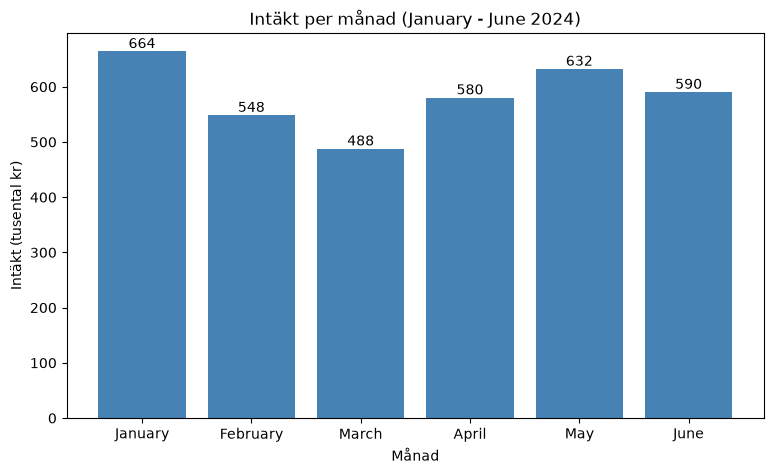

In [8]:
# Chart 1: Bar chart - revenue for each month

revenue_in_thousands = monthly_summary["total_revenue"] / 1000

fig = plot_bar(
    monthly_summary["month_name"],
    revenue_in_thousands,
    "Intäkt per månad (January - June 2024)",
    "Månad",
    "Intäkt (tusental kr)"
)
plt.show()

In [9]:
# Sales by week

weekly_summary = summarize_revenue(df, ["week_number"])

week_dates = (
    df.groupby("week_number")
    .agg(
        first_day = ("date", "min"),
        last_day = ("date", "max"),
    )
    .reset_index()
)

weekly_summary["week_label"] = (
    week_dates["first_day"].dt.strftime("%d %b")
    + " - "
    + week_dates["last_day"].dt.strftime("%d %b")
)

print("Antal veckor:", len(weekly_summary))
weekly_summary[["week_label", "total_revenue", "total_units", "order_count", "average_order_value"]].head()

Antal veckor: 26


,week_label,total_revenue,total_units,order_count,average_order_value
0,01 Jan - 07 Jan,161119.04,326,108,1491.84
1,08 Jan - 14 Jan,136568.68,265,81,1686.03
2,15 Jan - 21 Jan,147225.11,319,104,1415.63
3,22 Jan - 28 Jan,165832.80,328,108,1535.49
4,29 Jan - 04 Feb,124154.34,247,89,1394.99


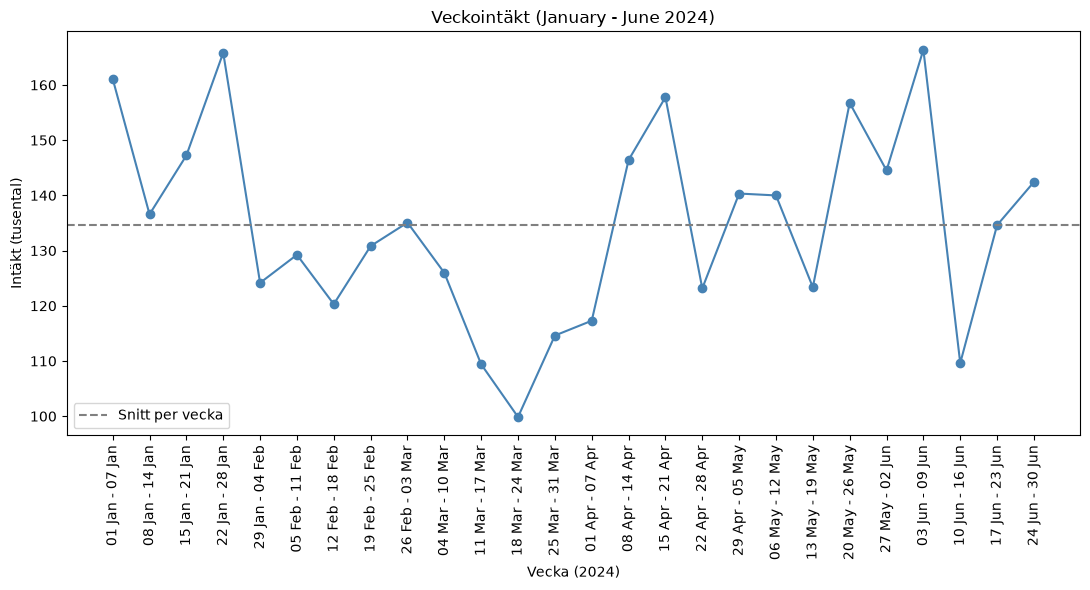

In [ ]:
# Chart 2: Line chart - revenue for each week with the average line

revenue_in_thousands = weekly_summary["total_revenue"] / 1000

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(weekly_summary["week_label"], revenue_in_thousands, color="steelblue", marker="o")
ax.axhline(revenue_in_thousands.mean(), color="gray", linestyle="--", label="Snitt per vecka")
ax.set_title("Veckointäkt (January - June 2024)")
ax.set_xlabel("Vecka (2024)")
ax.set_ylabel("Intäkt (tusental kr)")
ax.tick_params(axis="x", rotation=90)
ax.legend()
fig.tight_layout()

plt.show()

In [11]:
# Sales by weekday

weekday_summary = summarize_revenue(df, ["weekday_number", "weekday_name"])
weekday_summary.drop(columns="weekday_number")

,weekday_name,total_revenue,total_units,order_count,average_order_value
0,Monday,527263.73,1115,368,1432.78
1,Tuesday,512978.35,1037,354,1449.09
2,Wednesday,502661.61,1063,346,1452.78
3,Thursday,518871.71,1098,361,1437.32
4,Friday,501396.53,1082,357,1404.47
5,Saturday,481483.77,1052,355,1356.29
6,Sunday,458111.53,1016,359,1276.08


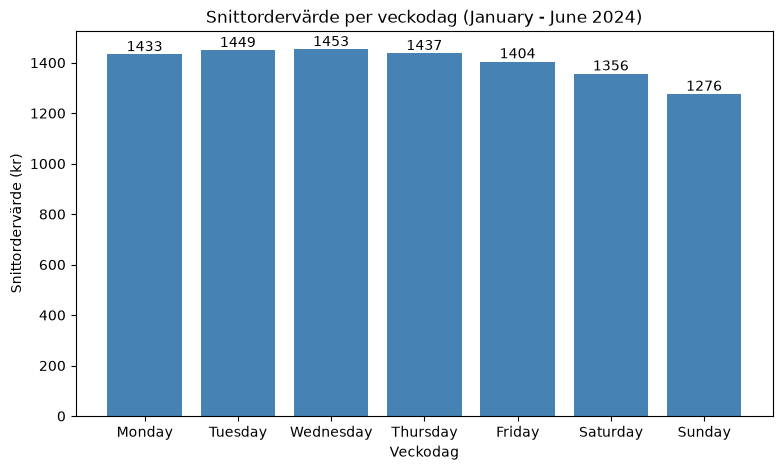

In [12]:
# Chart 3: Bar chart - average order value for each weekday

fig = plot_bar(
    weekday_summary["weekday_name"],
    weekday_summary["average_order_value"],
    "Snittordervärde per veckodag (January - June 2024)",
    "Veckodag",
    "Snittordervärde (kr)"
)
plt.show()

In [13]:
# Mean and median of daily and weekly revenue

daily_summary = summarize_revenue(df, ["date"])

print("Intäkt per dag - snitt:", round(daily_summary["total_revenue"].mean()))
print("Intäkt per dag - median:", round(daily_summary["total_revenue"].median()))
print("Intäkt per vecka - snitt:", round(weekly_summary["total_revenue"].mean()))
print("Intäkt per vecka - median:", round(weekly_summary["total_revenue"].median()))

Intäkt per dag - snitt: 19246
Intäkt per dag - median: 18865
Intäkt per vecka - snitt: 134722
Intäkt per vecka - median: 134838


### Sammanfattning: när säljer vi?
Året börjar starkt, mars tar paus och söndagen handlar smått.
- **Månad:** Januari är starkast (ca 664 000) och mars svagast (ca 488 000), drygt en fjärdedel lägre.
- **Varför mars?** Antalet ordrar är normalt (411), men snittordervärdet är lägst (ca 1 186 mot 1 340–1 540 andra månader). Kunderna handlar alltså för mindre per order. Antalet enheter per order är också lägst i mars (2,72 mot 2,90–3,16).
- **Vecka:** Snittet är ca 135 000 per vecka. Vecka 12 (18–24 mars) är lägst med ca 100 000, och vecka 10–14 (4 mars – 7 april) ligger under snittet.
- **Veckodag:** Måndag ger mest intäkt (ca 527 000) och söndag minst (ca 458 000). Snittordervärdet tenderar att vara lägre på söndagar, ca 12 % under måndag–torsdag, fast antalet ordrar är lika många.
- **Tips till ledningen:** Testa kampanjer som höjer ordervärdet i mars och på söndagar, till exempel paketerbjudanden eller fri frakt över en viss summa.
- **Försiktighet:** Vi har bara sex månader, så vi vet inte om mönstret beror på säsong eller om det är en engångsgrej.

### Hur ser en typisk order ut?

In [14]:
# Sammanfatta spridningen: antal, medelvärde, standardavvikelse,
# min, kvartiler (25 %, 50 %, 75 %) och max
# Funktionen order_spread finns i src/order_metrics.py

order_spread(df)

count    2500.00
mean     1401.11
std      1166.94
min        50.00
25%       577.96
50%      1088.69
75%      1884.75
max      9192.60
Name: revenue, dtype: float64

In [15]:
# Räkna ut gränsen för ovanligt stora ordrar med IQR-regeln:
# övre gräns = Q3 + 1,5 * (Q3 - Q1)
q1 = df["revenue"].quantile(0.25)
q3 = df["revenue"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

# Hämta de avvikande ordrarna med funktionen från src/order_metrics.py
outliers = find_outliers(df)

print("Övre gräns (kr):",round(upper_limit,2))
print("Antal avvikande ordrar:",len(outliers))
print("Andel av alla ordrar:",round(len(outliers) / len(df)*100, 1), "%")

Övre gräns (kr): 3844.94
Antal avvikande ordrar: 111
Andel av alla ordrar: 4.4 %


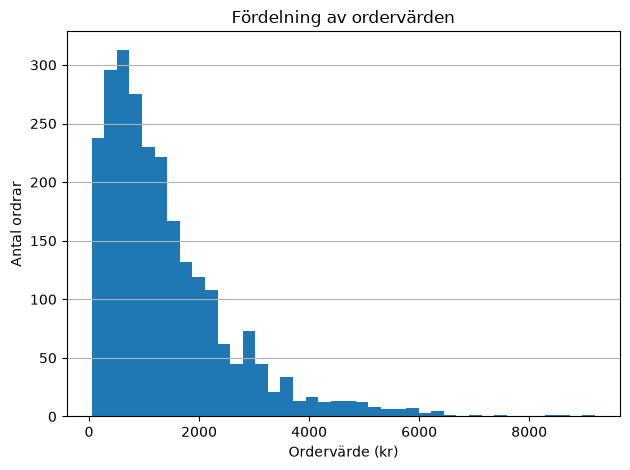

In [16]:
# Rita histogram över ordervärden (40 staplar, varje stapel är ett prisintervall)
fig, ax = plt.subplots()

# Titel och axeltext
ax.hist(df["revenue"].dropna(), bins = 40)
ax.set_title("Fördelning av ordervärden")
ax.set_xlabel("Ordervärde (kr)")
ax.set_ylabel("Antal ordrar")

# Horisontella hjälplinjer gör det lättare att läsa av antalet
ax.grid(True, axis = "y")

# Justera marginalerna så att inget klipps bort, och visa figuren
plt.tight_layout()
plt.show()

Histogrammet visar fördelningen av ordervärden. De flesta ordrar ligger mellan 0 och 2 000 kr, och de vanligaste värdena ligger kring 500 till 800 kr. Den långa svansen åt höger visar att ett fåtal mycket stora ordrar höjer medelvärdet (AOV) över medianen

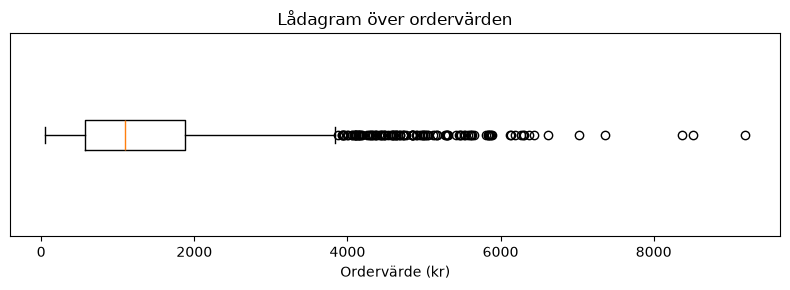

In [17]:
# Rita lådagram (boxplot) över ordervärden, liggande
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot(df["revenue"], orientation="horizontal")

# Titel och axeltext
ax.set_title("Lådagram över ordervärden")
ax.set_xlabel("Ordervärde (kr)")

# Ta bort den onödiga siffran på y-axeln
ax.set_yticks([])

# Justera marginalerna och visa figuren
plt.tight_layout()
plt.show()

Lådagrammet visar att hälften av alla ordrar ligger mellan cirka 580 och 1 900 kr, med medianen på cirka 1 090 kr. Prickarna till höger är de 111 ovanligt stora ordrarna (över 3 845 kr).

Rekommendation: Använd medianen (cirka 1 089 kr) som mått på en typisk order, och redovisa AOV (cirka 1 401 kr) tillsammans med den. Några få stora ordrar (över 3 845 kr, cirka 4 % av ordrarna) höjer snittet, så AOV ensamt ger en för hög bild av vad en vanlig kund köper.

### Topp 3 kategorier

,category,total
0,Electronics,1364228.07
1,Sports,734653.42
2,Clothing,586744.91


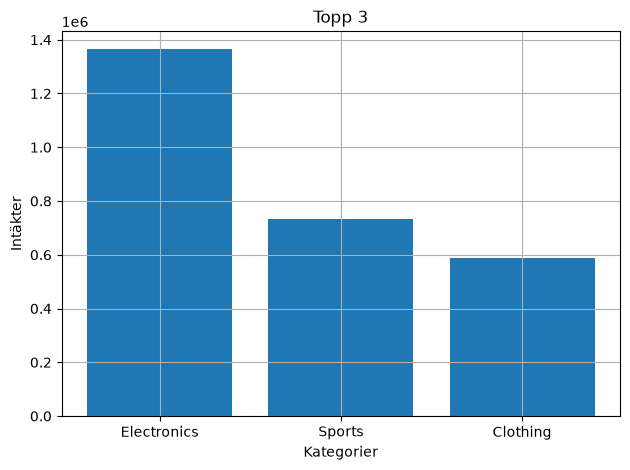

In [18]:
# Gör om listan till en DataFrame
df_kategorier = pd.DataFrame(intakter_per_kategori)

# Visar de tre första kategorierna
display(df_kategorier.head(3))

# Skapar en figur för stapeldiagrammet
fig, stapel = plt.subplots()

# Summerar intäkterna per kategori och väljer topp 3
category_total = df.groupby("category")["revenue"].sum().sort_values(ascending=False).head(3)

# Skapar stapeldiagrammet
stapel.bar(category_total.index, category_total.values)

# Lägger till titel, rubriker, rutnät och justerar layouten
stapel.set_title("Topp 3")
stapel.set_xlabel("Kategorier")
stapel.set_ylabel("Intäkter")
stapel.grid(True)
plt.tight_layout()